## 1. Suppose a dataset contains $m = 500$ houses, and each house is described by $n = 4$ features: square footage, bedrooms, bathrooms, and age. Write the dimensions of the design matrix $X$ and a single sample's column feature vector $\mathbf{x}^{(i)}$.

* Number of training examples (houses), $m = 500$
* Number of features per house, $n = 4$ (square footage, bedrooms, bathrooms, and age)

&nbsp;

* **Design Matrix ($X$):** $500 \times 4$
* **Single Sample Column Feature Vector ($\mathbf{x}^{(i)}$):** $4 \times 1$


---

### Explanation
1. **Design Matrix ($X$):** 
   Structured as $m \times n$, where each row corresponds to a single training example (house) and each column corresponds to a specific feature:
   $$X = \begin{bmatrix} 
   — & (\mathbf{x}^{(1)})^T & — \\ 
   — & (\mathbf{x}^{(2)})^T & — \\ 
   & \vdots & \\ 
   — & (\mathbf{x}^{(500)})^T & — 
   \end{bmatrix} \in \mathbb{R}^{500 \times 4}$$

2. **Single Sample Feature Vector ($\mathbf{x}^{(i)}$):** 
   Structured as $n \times 1$, representing all $4$ feature values for the $i$-th house as a column vector:
   $$\mathbf{x}^{(i)} = \begin{bmatrix} 
   x_1^{(i)} \\ 
   x_2^{(i)} \\ 
   x_3^{(i)} \\ 
   x_4^{(i)} 
   \end{bmatrix} \in \mathbb{R}^{4 \times 1}$$

> **Note:** If your convention includes an intercept/bias feature ($x_0^{(i)} = 1$) inside the matrices, the dimensions become **$500 \times 5$** for $X$ and **$5 \times 1$** for $\mathbf{x}^{(i)}$.


## 2. A linear regression model predicts housing prices using $\hat{y} = \mathbf{w}^T \mathbf{x} + b$, where $\mathbf{w} = \begin{pmatrix} 120 \\ 15000 \\ 10000 \\ -500 \end{pmatrix}$ and $b = 50000$. Compute the predicted price $\hat{y}$ for a house represented by $\mathbf{x} = \begin{pmatrix} 1500 \\ 3 \\ 2 \\ 10 \end{pmatrix}$.

In [74]:
import sympy as sp

w = sp.Matrix(
    [120,15000,10000,-500]
)
x = sp.Matrix(
    [1500,3,2,10]
)
b = 50000

In [75]:
print("w =", end=" ")
sp.pprint(w)

print('\nx = ', end=" ")
sp.pprint(x)

print(f'\nb = {b}')


w = ⎡ 120 ⎤
⎢     ⎥
⎢15000⎥
⎢     ⎥
⎢10000⎥
⎢     ⎥
⎣-500 ⎦

x =  ⎡1500⎤
⎢    ⎥
⎢ 3  ⎥
⎢    ⎥
⎢ 2  ⎥
⎢    ⎥
⎣ 10 ⎦

b = 50000


In [76]:
w_t = sp.Transpose(w).doit()
sp.pprint(w_t)

[120  15000  10000  -500]


In [77]:
sol = w_t.dot(x) + b
sp.pprint(sol)

290000


## 3. Explain mathematically why computing predictions for a batch of $10,000$ samples via matrix-vector multiplication $\hat{\mathbf{y}} = X\mathbf{w} + \mathbf{b}$ is preferred over iterating through each sample individually in Python.

**Matrix-vector multiplication ($\hat{\mathbf{y}} = X\mathbf{w} + \mathbf{b}$) eliminates Python interpreter overhead and unlocks parallel hardware acceleration, turning $10,000$ sequential steps into a single optimized block operation.**

### 1. Mathematical Formulation Comparison

Suppose we have $N = 10,000$ samples, each with $D$ features.

* **Iterative (Scalar) Approach:**
  A loop computes each prediction $\hat{y}_i$ sequentially through $10,000$ separate dot products:
  $$\hat{y}_i = \mathbf{x}_i^\top \mathbf{w} + b = \sum_{j=1}^{D} x_{ij} w_j + b \quad \text{for } i = 1, 2, \dots, 10,000$$

* **Vectorized (Matrix-Vector) Approach:**
  Stacking all $10,000$ row vectors into a single matrix $X \in \mathbb{R}^{10,000 \times D}$ consolidates all $10,000$ dot products into one linear transformation:
  $$\hat{\mathbf{y}} = X\mathbf{w} + b\mathbf{1}_{10,000}$$
  where $\mathbf{w} \in \mathbb{R}^{D \times 1}$ is the weight vector, and $\mathbf{1}_{10,000} \in \mathbb{R}^{10,000 \times 1}$ is a column vector of ones that mathematically represents broadcasting the scalar bias $b$ to every sample.

---

### 2. Computational & Hardware Advantages

Although both approaches require the exact same total number of floating-point operations ($\mathcal{O}(ND)$ FLOPs), vectorization is drastically faster for three reasons:

* **Elimination of Python Interpreter Overhead:**
  Python is dynamically typed and interpreted. Running a loop $10,000$ times forces Python to perform type-checking, dynamic dispatch, and pointer lookups on every iteration. Matrix multiplication hands the entire $10,000 \times D$ array to pre-compiled C/C++ or Fortran routines (via BLAS/LAPACK in NumPy) in a single call.
* **SIMD (Single Instruction, Multiple Data) Parallelism:**
  Modern CPUs and GPUs use SIMD vector registers to execute the same arithmetic instruction (such as fused multiply-add) across multiple data points simultaneously within a single clock cycle, rather than processing one scalar at a time.
* **Contiguous Memory & Cache Locality:**
  The matrix $X$ occupies a contiguous block of RAM. Vectorized operations load sequential chunks of $X$ directly into fast L1/L2 CPU caches, maximizing spatial locality. Iterating over Python lists or objects involves chasing scattered memory pointers, resulting in frequent cache misses and memory latency.


## 4. In an image classification task, a grayscale image has a resolution of $28 \times 28$ pixels. When flattened into a feature vector $\mathbf{x} \in \mathbb{R}^n$ for a dense neural network layer, what is $n$, and what does each entry $x_j$ represent?

For a $28 \times 28$ grayscale image flattened into a feature vector $\mathbf{x} \in \mathbb{R}^n$:

### 1. Dimension $n$
* **Value:** $n = 784$
* **Explanation:** Flattening converts the 2D pixel grid into a 1D column vector, so $n$ equals the total number of pixels in the image:
  $$n = 28 \times 28 = 784$$

### 2. Meaning of each entry $x_j$
* **Representation:** Each entry $x_j$ (for $j = 1, 2, \dots, 784$) represents the **pixel intensity (brightness)** of a single specific pixel in the image.
* **Typical Scale:** Since the image is grayscale (1 channel), each $x_j$ is a single scalar value—commonly an integer ranging from $0$ (black) to $255$ (white), or a normalized floating-point value in $[0, 1]$.


## 5. Consider two user preference vectors in a recommendation system: $\mathbf{u}_1 = \begin{pmatrix} 5 \\ 1 \\ 0 \end{pmatrix}$ and $\mathbf{u}_2 = \begin{pmatrix} 4 \\ 1 \\ 0 \end{pmatrix}$, where dimensions represent ratings for Action, Comedy, and Horror movies. Explain how representing users as vectors in $\mathbb{R}^3$ allows an ML model to quantify similarity between $\mathbf{u}_1$ and $\mathbf{u}_2$.

Representing users as vectors in $\mathbb{R}^{3}$ maps their preferences into a 3-dimensional geometric space, allowing a machine learning model to quantify similarity using vector distances or angles (such as cosine similarity and Euclidean distance).


In [124]:
import numpy as np
import matplotlib.pyplot as plt


u1 = np.array([5, 1, 0])
u2 = np.array([4, 1, 0])

In [125]:
dot_product = np.dot(u1, u2)
norm_u1 = np.linalg.norm(u1)
norm_u2 = np.linalg.norm(u2)

cosine_sim = dot_product / (norm_u1 * norm_u2)
print(cosine_sim)

0.9988681377244377


In [126]:
dist = np.linalg.norm(u1 - u2)

sp.pprint(dist)

1.0


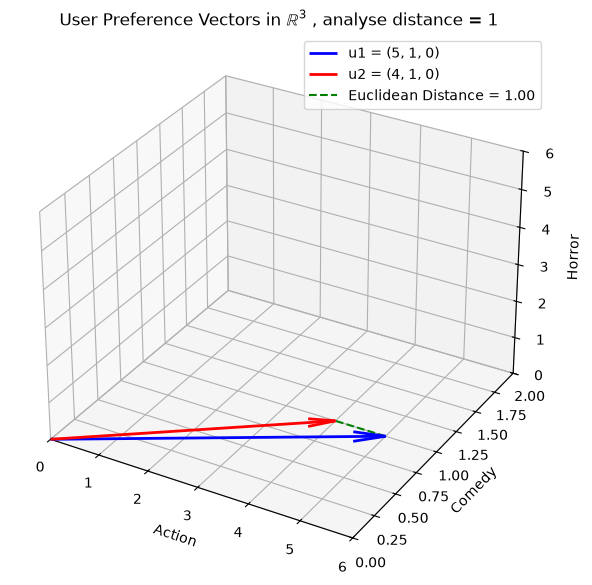

In [ ]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.quiver(
    0, 0, 0,
    u1[0], u1[1], u1[2],
    color='blue',
    arrow_length_ratio=0.1,
    linewidth=2,
    label=f"u1 = {tuple(u1.tolist())}",
)

ax.quiver(
    0, 0, 0,
    u2[0], u2[1], u2[2],
    color='red',
    arrow_length_ratio=0.1,
    linewidth=2,
    label=f"u2 = {tuple(u2.tolist())}",
)

ax.plot(
    [u1[0], u2[0]],
    [u1[1], u2[1]],
    [u1[2], u2[2]],
    'g--',
    linewidth=1.5,
    label=f"Euclidean Distance = {float(dist):.2f}",
)

ax.set_xlim([0, 6])
ax.set_ylim([0, 2])
ax.set_zlim([0, 6])

ax.set_xlabel("Action")
ax.set_ylabel("Comedy")
ax.set_zlabel("Horror")
ax.set_title(r"User Preference Vectors in $\mathbb{R}^3$ , analyse distance = 1")
ax.legend()

plt.tight_layout()
plt.show()

## 3. Let $\mathbf{v}_1 = \begin{pmatrix} 1 \\ 2 \end{pmatrix}$ and $\mathbf{v}_2 = \begin{pmatrix} -2 \\ -4 \end{pmatrix}$. Determine whether any scalar combination $c_1\mathbf{v}_1 + c_2\mathbf{v}_2$ can produce the vector $\mathbf{b} = \begin{pmatrix} 3 \\ 5 \end{pmatrix}$, and explain why geometrically.